# Give Me Some Credit: EDA

By: Carlos, Alejandro and Gregorio

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/cs-training.csv")
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
# The first column is only the row number added by Kaggle, so we drop it
df = df.drop(columns="Unnamed: 0")
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 1. Data inspection
We have to understand the structure of the dataset and its variables

In [4]:
df.shape

(150000, 11)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [6]:
# Count the missing values of each column
df.isna().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

The dataset has 150,000 rows and 11 columns, all numeric, so we do not need to encode categories. MonthlyIncome has 29,731 missing values (19.8%) and NumberOfDependents has 3,924 (2.6%). The rest of the columns are complete. We will decide how to fill them in the missing values section, and we will apply it after the train/test split.

In [7]:
# Rows that are exactly the same in all columns
df.duplicated().sum()

np.int64(609)

In [8]:
# Same number as a percentage of the dataset
df.duplicated().sum() / len(df) * 100

np.float64(0.406)

In [9]:
# Show every copy of the duplicated rows, sorted so the identical ones are together
dups = df[df.duplicated(keep=False)].sort_values(list(df.columns))
dups.head(10)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
134365,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
137102,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
25632,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
83552,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
139345,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
100594,0,0.0,21,0,0.0,NaN,1,0,0,0,0.0
127724,0,0.0,21,0,0.0,NaN,1,0,0,0,0.0
44006,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
54653,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
53012,0,0.0,22,0,0.0,1.0,2,0,0,0,0.0


In [10]:
# Are the duplicates real copies of one row, or simple profiles that many different people share?
# We compare the duplicated rows with the whole dataset
extra_copies = df[df.duplicated()]

print("Duplicated rows:", len(extra_copies))
print("DebtRatio equal to 0 (%):", round((extra_copies["DebtRatio"] == 0).mean() * 100, 1))
print("MonthlyIncome missing or <= 1,000 (%):", round((extra_copies["MonthlyIncome"].isna() | (extra_copies["MonthlyIncome"] <= 1000)).mean() * 100, 1))
print("2 or fewer open credit lines (%): duplicates", round((extra_copies["NumberOfOpenCreditLinesAndLoans"] <= 2).mean() * 100, 1),
      "| whole dataset", round((df["NumberOfOpenCreditLinesAndLoans"] <= 2).mean() * 100, 1))
print("Delinquent customers (%): duplicates", round(extra_copies["SeriousDlqin2yrs"].mean() * 100, 2),
      "| whole dataset", round(df["SeriousDlqin2yrs"].mean() * 100, 2))

Duplicated rows: 609
DebtRatio equal to 0 (%): 98.2
MonthlyIncome missing or <= 1,000 (%): 98.5
2 or fewer open credit lines (%): duplicates 77.3 | whole dataset 8.7
Delinquent customers (%): duplicates 2.79 | whole dataset 6.68


There are 609 duplicated rows (0.41%). The dataset has no customer ID, so we checked what kind of rows they are. Almost all of them are very simple profiles: DebtRatio is 0 in 98% of them, 98.5% have no income or an income of 1,000 or less, and 77% have two or fewer open credit lines (against 8.7% in the whole dataset). Their delinquency rate is also lower (2.79% against 6.68%). They do not look like the same record copied by mistake, but like different people, mostly young customers with almost no credit history, who share the same simple values.

Decision: we keep the duplicated rows. Dropping them would remove real customers of this type, and the effect on the data is very small anyway.

In [11]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


Some values look wrong. age has a minimum of 0, and the late-payment counters have a maximum of 98, far from their usual values. RevolvingUtilizationOfUnsecuredLines should be between 0 and 1, but its maximum is about 50,708. DebtRatio (maximum 329,664) and MonthlyIncome (maximum 3,008,750) also have extreme maximums, and MonthlyIncome has a minimum of 0. We only detect these problems here: the errors will be fixed in the next section and the outliers after that.

## 2. Target distribution
The target variable is SeriousDlqin2yrs: 1 if the customer had a serious delinquency (90 days or more past due) in the next two years, 0 if not

In [12]:
# Number of customers in each class
df["SeriousDlqin2yrs"].value_counts()

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

In [13]:
# Same, as a percentage
df["SeriousDlqin2yrs"].value_counts(normalize=True) * 100

SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64

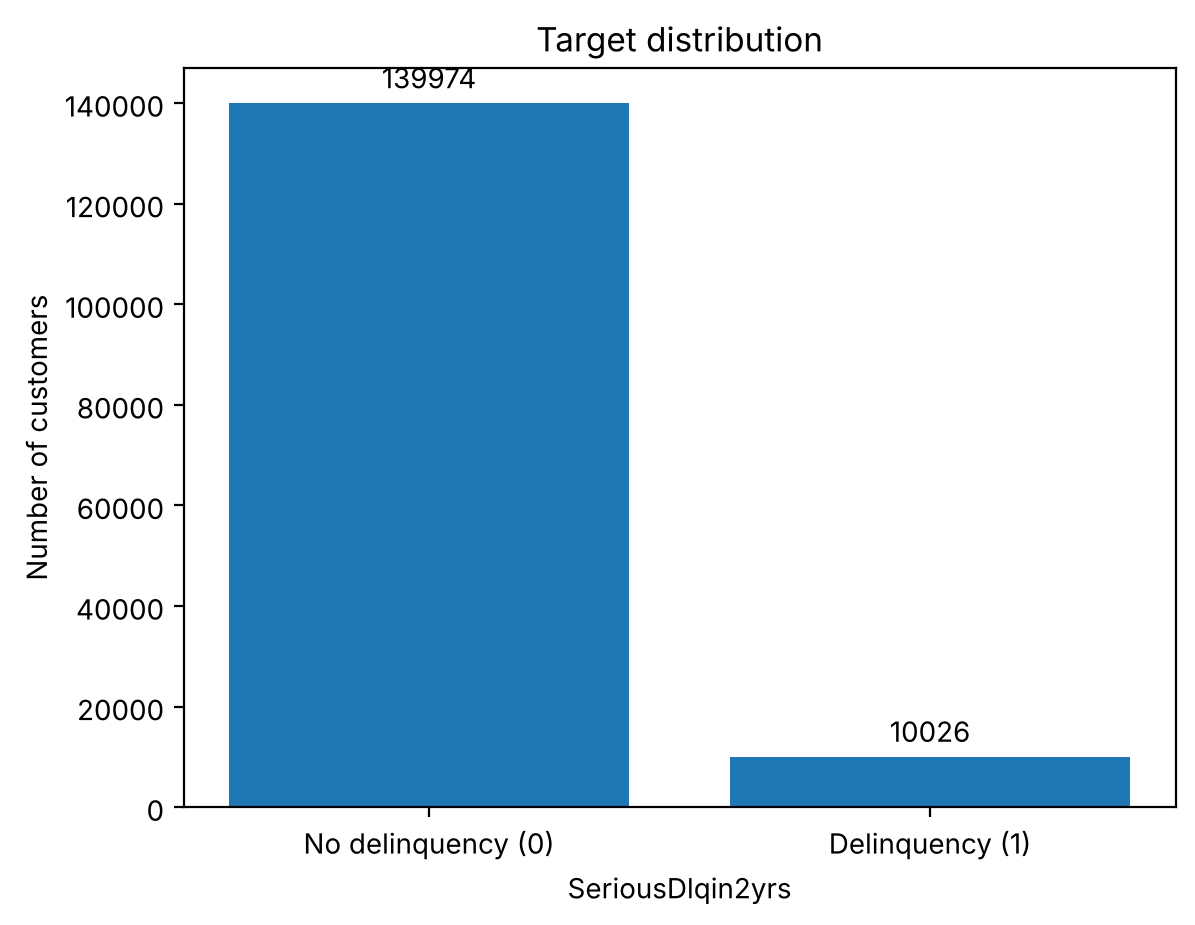

In [14]:
# Bar chart of the two classes
counts = df["SeriousDlqin2yrs"].value_counts()
bars = plt.bar(["No delinquency (0)", "Delinquency (1)"], counts.values)

# Labels with the number of customers on top of each bar
plt.bar_label(bars, padding=3)

plt.xlabel("SeriousDlqin2yrs")
plt.ylabel("Number of customers")
plt.title("Target distribution")
plt.show()

In [15]:
# Accuracy of a "model" that always predicts class 0 (no delinquency)
counts[0] / len(df) * 100

np.float64(93.316)

The target is imbalanced: 10,026 customers (6.68%) had a serious delinquency and 139,974 (93.32%) did not. A model that always predicts "no delinquency" would have 93.3% accuracy and detect no one, so accuracy is not a good metric here. We will use metrics such as ROC-AUC, PR-AUC or recall, and we will split train and test with stratification so both keep the same percentage of delinquent customers.